Predicting Stock Market Prices	Perform an in-depth decomposition of the TSLA time series into its underlying trend, seasonality, and residual components, and analyze each component to understand long-term patterns and irregular fluctuations in stock prices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from scipy import stats

In [2]:
# Load dataset and sort chronologically
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Inspect trading-day structure and check for duplicate timestamps
df['DayOfWeek'] = df['Date'].dt.day_name()
dup_dates = df[df.duplicated(subset=['Date'], keep=False)]

print(f"Total Rows: {len(df)} | Date Range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Duplicate Date Entries Found: {len(dup_dates)} rows ({dup_dates['Date'].dt.date.unique().tolist()})")
print("\nTrading Day Distribution:")
print(df['DayOfWeek'].value_counts().to_string())

Total Rows: 100 | Date Range: 2025-01-02 to 2025-05-14
Duplicate Date Entries Found: 10 rows ([datetime.date(2025, 1, 14), datetime.date(2025, 1, 27), datetime.date(2025, 2, 5), datetime.date(2025, 3, 14), datetime.date(2025, 4, 1)])

Trading Day Distribution:
DayOfWeek
Tuesday      21
Friday       20
Monday       20
Wednesday    20
Thursday     19


In [3]:
# Period = 5 represents a standard 5-trading-day market week
PERIOD = 5

# 1. Classical Additive & Multiplicative Decomposition
add_decomp = seasonal_decompose(df['Close'], model='additive', period=PERIOD, extrapolate_trend='freq')
mul_decomp = seasonal_decompose(df['Close'], model='multiplicative', period=PERIOD, extrapolate_trend='freq')

# 2. Robust STL Decomposition (handles price jumps/outliers cleanly via LOESS smoothing)
stl = STL(df['Close'], period=PERIOD, robust=True)
stl_res = stl.fit()

# Store STL components in DataFrame for quantitative analysis
df['STL_Trend'] = stl_res.trend
df['STL_Seasonal'] = stl_res.seasonal
df['STL_Resid'] = stl_res.resid
df['Add_Resid'] = add_decomp.resid
df['Mul_Resid'] = mul_decomp.resid

print("Decomposition complete. Sample extracted STL components:")
print(df[['Date', 'Close', 'STL_Trend', 'STL_Seasonal', 'STL_Resid']].head(7).round(3).to_string(index=False))

Decomposition complete. Sample extracted STL components:
      Date  Close  STL_Trend  STL_Seasonal  STL_Resid
2025-01-02 381.88    385.023        -4.262      1.119
2025-01-03 376.36    382.665        -4.734     -1.572
2025-01-06 380.68    380.311         0.296      0.073
2025-01-07 386.06    377.967         7.878      0.215
2025-01-08 375.53    375.659        -0.455      0.326
2025-01-09 368.56    373.454        -3.336     -1.558
2025-01-10 369.47    371.685        -2.964      0.749


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10500\970714868.py:5: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  add_decomp = seasonal_decompose(df['Close'], model='additive', period=PERIOD, extrapolate_trend='freq')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10500\970714868.py:6: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  mul_decomp = seasonal_decompose(df['Close'], model='multiplicative', period=PERIOD, extrapolate_trend='freq')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10500\970714868.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(df[['Date', 'Close', 'STL_Trend', 'STL_Seasonal', 'STL_Resid']].head(7).round(3).to_string(index=False))


In [4]:
# Hyndman & Athanasopoulos Strength Metrics (0 = none, 1 = pure deterministic signal)
var_resid = np.var(df['STL_Resid'])
var_trend_resid = np.var(df['STL_Trend'] + df['STL_Resid'])
var_seas_resid = np.var(df['STL_Seasonal'] + df['STL_Resid'])

strength_trend = max(0.0, 1.0 - (var_resid / var_trend_resid))
strength_seasonality = max(0.0, 1.0 - (var_resid / var_seas_resid))

# Component Summary Table
comp_summary = pd.DataFrame({
    'Component': ['Observed Close', 'STL Trend (T_t)', 'STL Seasonal (S_t)', 'STL Residual (R_t)'],
    'Mean': [df['Close'].mean(), df['STL_Trend'].mean(), df['STL_Seasonal'].mean(), df['STL_Resid'].mean()],
    'Std_Dev': [df['Close'].std(), df['STL_Trend'].std(), df['STL_Seasonal'].std(), df['STL_Resid'].std()],
    'Min': [df['Close'].min(), df['STL_Trend'].min(), df['STL_Seasonal'].min(), df['STL_Resid'].min()],
    'Max': [df['Close'].max(), df['STL_Trend'].max(), df['STL_Seasonal'].max(), df['STL_Resid'].max()]
})

print("--- STL Component Statistical Summary ---")
print(comp_summary.round(3).to_string(index=False))
print(f"\nStrength of Trend (F_T)       : {strength_trend:.4f} ({strength_trend*100:.2f}% variance explained over residuals)")
print(f"Strength of Seasonality (F_S) : {strength_seasonality:.4f} ({strength_seasonality*100:.2f}% variance explained over residuals)")

# Average Intra-Week (Day-of-Week) Seasonal Profile
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
weekday_effect = df.groupby('DayOfWeek')['STL_Seasonal'].agg(['mean', 'std']).reindex(weekday_order)
print("\n--- Average Intra-Week Seasonal Effect ($) ---")
print(weekday_effect.round(4).to_string())

--- STL Component Statistical Summary ---
         Component    Mean  Std_Dev     Min     Max
    Observed Close 396.188   14.710 363.540 420.550
   STL Trend (T_t) 395.774   13.643 369.380 414.340
STL Seasonal (S_t)  -0.118    2.420 -10.030   7.878
STL Residual (R_t)   0.531    3.257  -6.349  11.659

Strength of Trend (F_T)       : 0.9506 (95.06% variance explained over residuals)
Strength of Seasonality (F_S) : 0.1721 (17.21% variance explained over residuals)

--- Average Intra-Week Seasonal Effect ($) ---
             mean     std
DayOfWeek                
Monday     0.2069  0.9015
Tuesday    0.3043  2.3381
Wednesday -1.6969  2.7309
Thursday   0.1833  2.5838
Friday     0.4043  2.6199


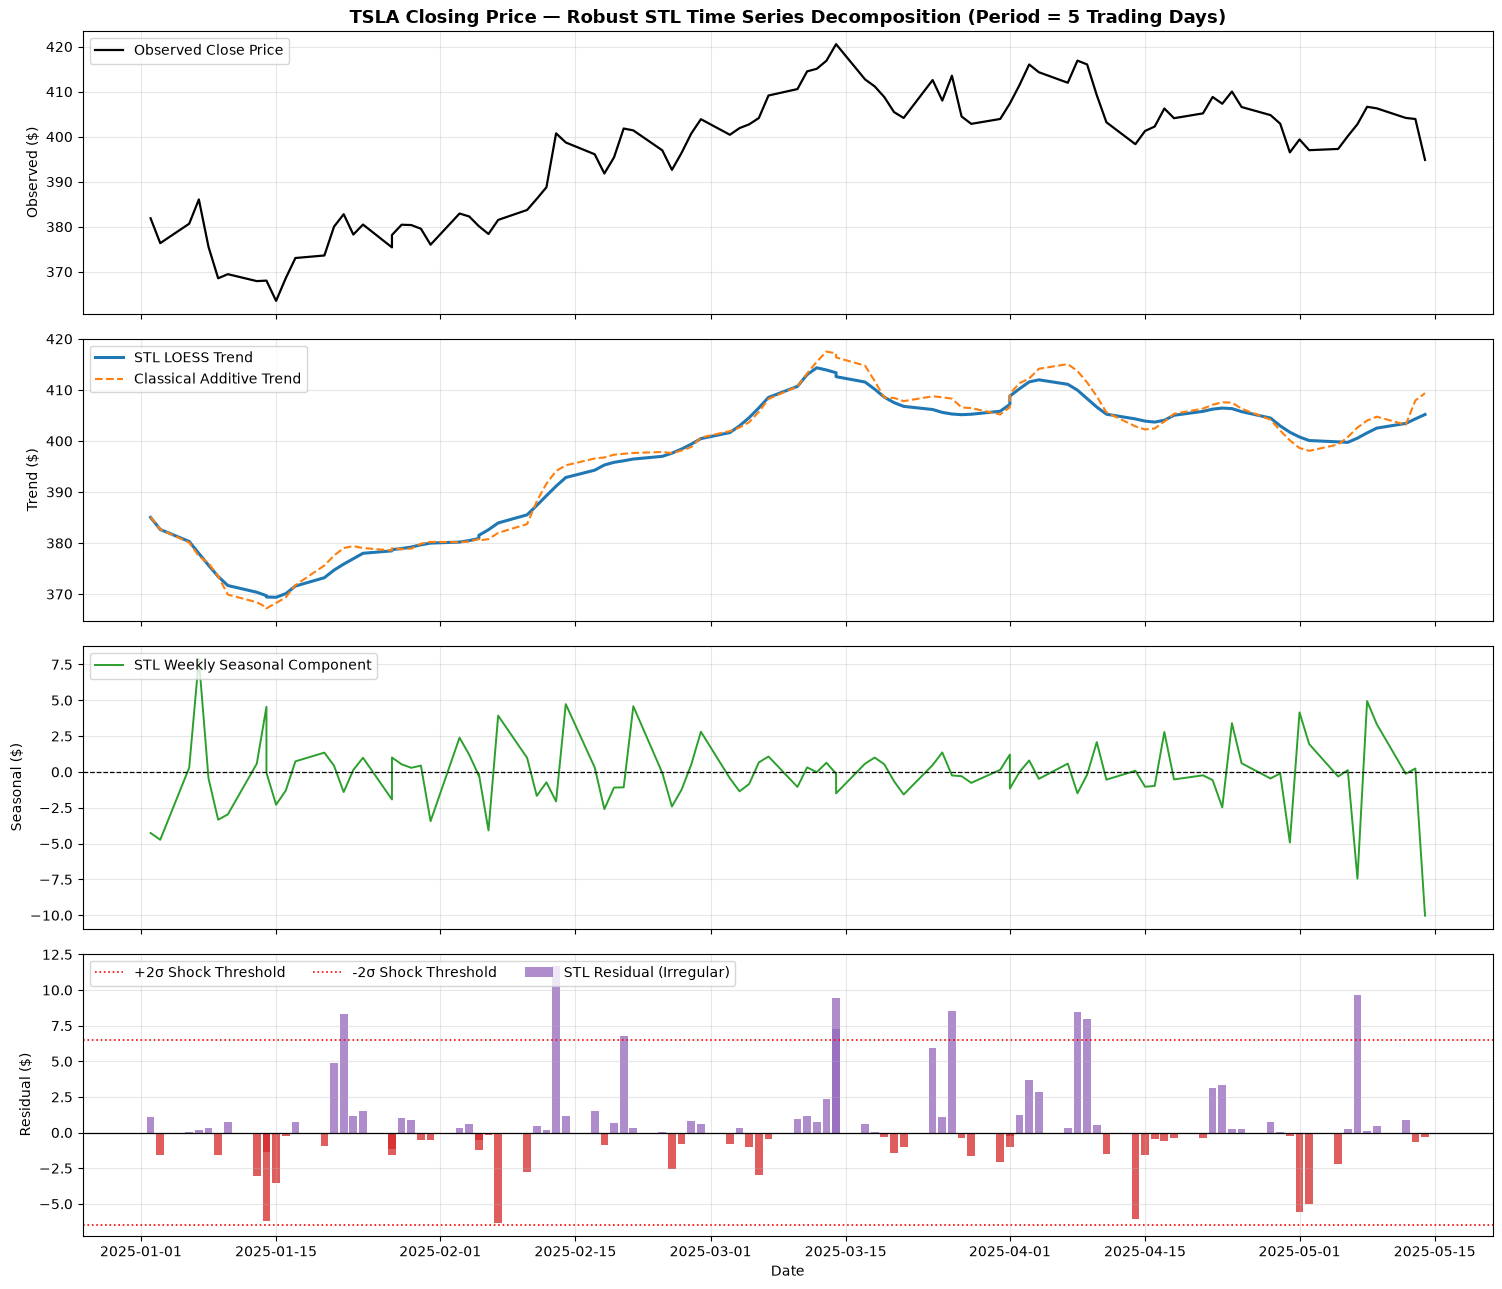

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=True)

# 1. Observed TSLA Closing Price
axes[0].plot(df['Date'], df['Close'], color='black', linewidth=1.6, label='Observed Close Price')
axes[0].set_title('TSLA Closing Price — Robust STL Time Series Decomposition (Period = 5 Trading Days)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Observed ($)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# 2. Long-Term Underlying Trend Component (STL vs. Classical Moving-Average Trend)
axes[1].plot(df['Date'], df['STL_Trend'], color='#1f77b4', linewidth=2.2, label='STL LOESS Trend')
axes[1].plot(df['Date'], add_decomp.trend, color='#ff7f0e', linestyle='--', linewidth=1.5, label='Classical Additive Trend')
axes[1].set_ylabel('Trend ($)')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

# 3. Cyclical / Intra-Week Seasonal Component
axes[2].plot(df['Date'], df['STL_Seasonal'], color='#2ca02c', linewidth=1.4, label='STL Weekly Seasonal Component')
axes[2].axhline(0, color='black', linestyle='--', linewidth=0.9)
axes[2].set_ylabel('Seasonal ($)')
axes[2].legend(loc='upper left')
axes[2].grid(True, alpha=0.3)

# 4. Irregular Residual Component (Noise & Shock Detection)
resid_std = df['STL_Resid'].std()
axes[3].bar(df['Date'], df['STL_Resid'], color=np.where(df['STL_Resid'] >= 0, '#9467bd', '#d62728'), alpha=0.75, width=0.8, label='STL Residual (Irregular)')
axes[3].axhline(0, color='black', linewidth=0.9)
axes[3].axhline(2 * resid_std, color='red', linestyle=':', linewidth=1.2, label='+2σ Shock Threshold')
axes[3].axhline(-2 * resid_std, color='red', linestyle=':', linewidth=1.2, label='-2σ Shock Threshold')
axes[3].set_ylabel('Residual ($)')
axes[3].set_xlabel('Date')
axes[3].legend(loc='upper left', ncol=3)
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

--- Irregular Residual Shocks (|Z| > 2.0): 11 Trading Days ---
      Date DayOfWeek  Close  STL_Trend  STL_Seasonal  STL_Resid  Resid_Z
2025-01-14   Tuesday 368.04     369.69          4.54      -6.20    -2.07
2025-01-22 Wednesday 382.79     375.88         -1.41       8.32     2.39
2025-02-07    Friday 381.52     383.94          3.93      -6.35    -2.11
2025-02-13  Thursday 400.75     391.15         -2.06      11.66     3.42
2025-03-14    Friday 420.55     413.37         -0.12       7.30     2.08
2025-03-14    Friday 420.55     412.60         -1.50       9.45     2.74
2025-03-26 Wednesday 413.54     405.28         -0.25       8.51     2.45
2025-04-08   Tuesday 416.90     409.96         -1.49       8.43     2.43
2025-04-09 Wednesday 416.05     408.29         -0.19       7.95     2.28
2025-04-14    Monday 398.34     404.32          0.08      -6.06    -2.02
2025-05-07 Wednesday 402.78     400.56         -7.45       9.67     2.81


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10500\108918590.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(anomalies.round(2).to_string(index=False))
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10500\108918590.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='DayOfWeek', y='STL_Seasonal', order=weekday_order, palette='Set2', ax=axes[1])


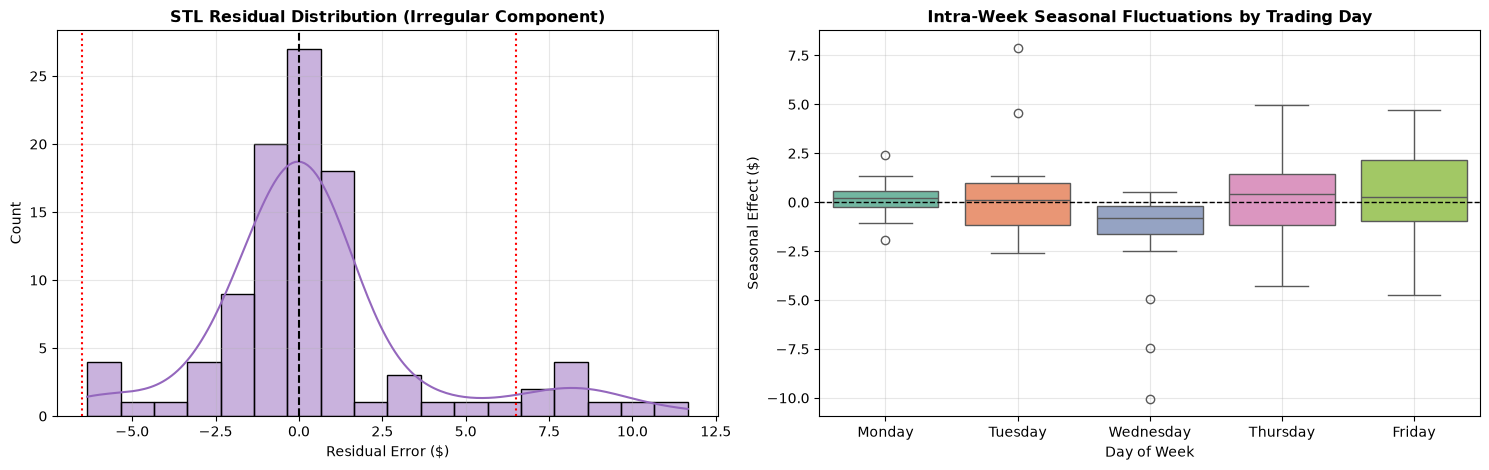

In [6]:
# Identify irregular price shock dates where |Residual Z-score| > 2
df['Resid_Z'] = (df['STL_Resid'] - df['STL_Resid'].mean()) / df['STL_Resid'].std()
anomalies = df[df['Resid_Z'].abs() > 2][['Date', 'DayOfWeek', 'Close', 'STL_Trend', 'STL_Seasonal', 'STL_Resid', 'Resid_Z']]

print(f"--- Irregular Residual Shocks (|Z| > 2.0): {len(anomalies)} Trading Days ---")
print(anomalies.round(2).to_string(index=False))

# Diagnostic Plots: Residual Distribution & Additive vs. Multiplicative Residual Stability
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Left: Residual Histogram + KDE
sns.histplot(df['STL_Resid'], bins=18, kde=True, color='#9467bd', ax=axes[0])
axes[0].axvline(0, color='black', linestyle='--')
axes[0].axvline(2 * resid_std, color='red', linestyle=':')
axes[0].axvline(-2 * resid_std, color='red', linestyle=':')
axes[0].set_title('STL Residual Distribution (Irregular Component)', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Residual Error ($)')
axes[0].grid(True, alpha=0.3)

# Right: Day-of-Week Seasonal Boxplot
sns.boxplot(data=df, x='DayOfWeek', y='STL_Seasonal', order=weekday_order, palette='Set2', ax=axes[1])
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Intra-Week Seasonal Fluctuations by Trading Day', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Seasonal Effect ($)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()